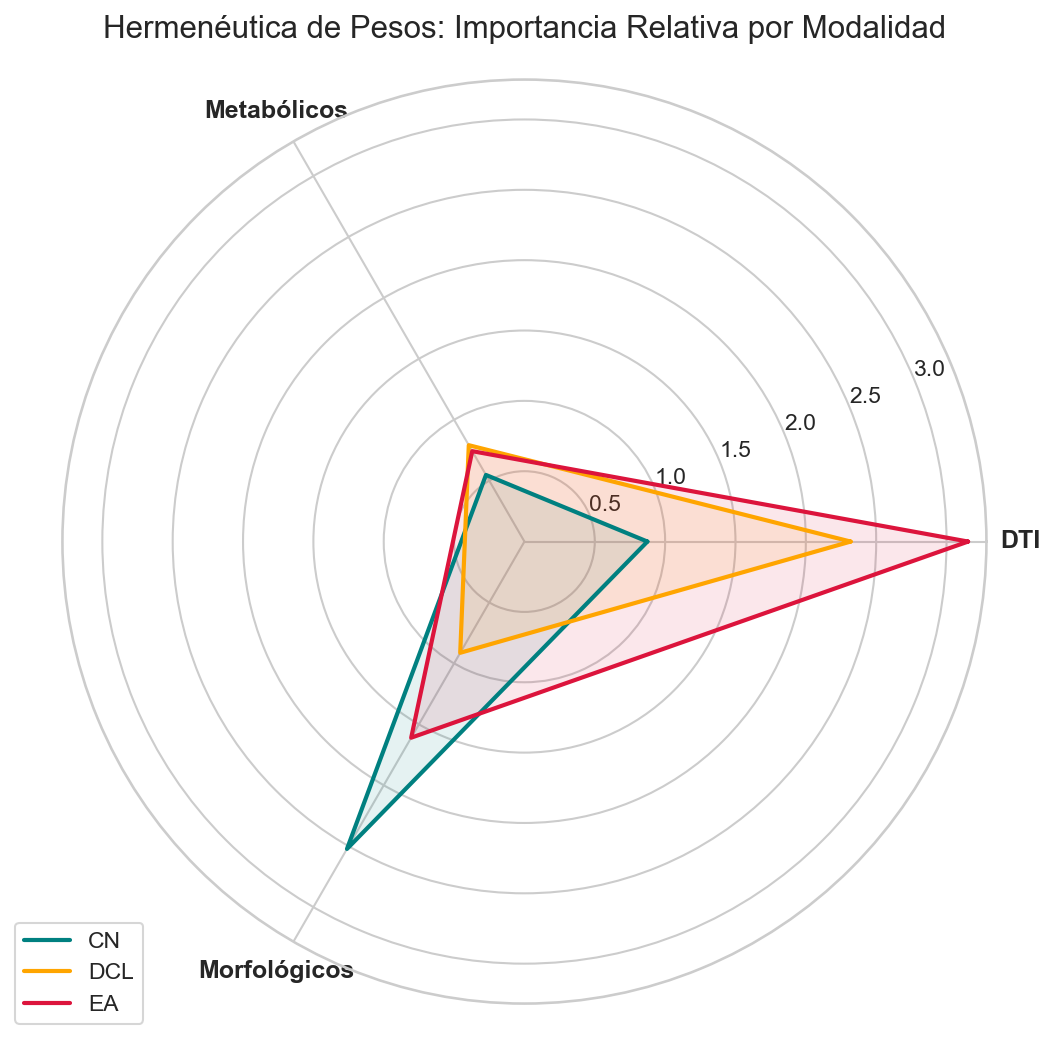

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# --- CONFIGURACIÓN DE ESTILO ---
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150


# ==========================================================
# GRÁFICO 1: RADAR DE LA JUSTA PROPORCIÓN (Pesos Stacking)
# ==========================================================
def grafico_radar_pesos(file_path='pesos_meta_modelo_mejores_por_modalidad.csv'):
    df = pd.read_csv(file_path)
    
    # Mapeos (ajusta según tus IDs de modalidad)
    modalities = {0: 'DTI', 1: 'Metabólicos', 2: 'Morfológicos'}
    class_names = {0: 'CN', 1: 'DCL', 2: 'EA'}
    
    # Agrupamos importancia por modalidad (suma absoluta de pesos por clase)
    df['Modality'] = (df['Modalidad_Prob'] // 3).map(modalities)
    df['ClassName'] = df['Clase'].map(class_names)
    
    # Calculamos importancia absoluta
    radar_df = df.groupby(['ClassName', 'Modality'])['Peso'].apply(lambda x: x.abs().sum()).unstack()
    
    # Configuración de Radar
    categories = list(radar_df.columns)
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    colors = {'CN': 'teal', 'DCL': 'orange', 'EA': 'crimson'}
    
    for i, row in radar_df.iterrows():
        values = row.values.flatten().tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=i, color=colors.get(i, 'blue'))
        ax.fill(angles, values, color=colors.get(i, 'blue'), alpha=0.1)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, size=12, fontweight='bold')
    plt.title('Hermenéutica de Pesos: Importancia Relativa por Modalidad', size=15, pad=20)
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.savefig(file_path[:-4]+'.png', bbox_inches='tight')
    plt.show()


# --- EJECUCIÓN ---
if __name__ == "__main__":
    # Generar Radar y Boxplot con tus archivos actuales
    try:
        grafico_radar_pesos()
    except Exception as e:
        print(f"Error al generar gráficos automáticos: {e}")

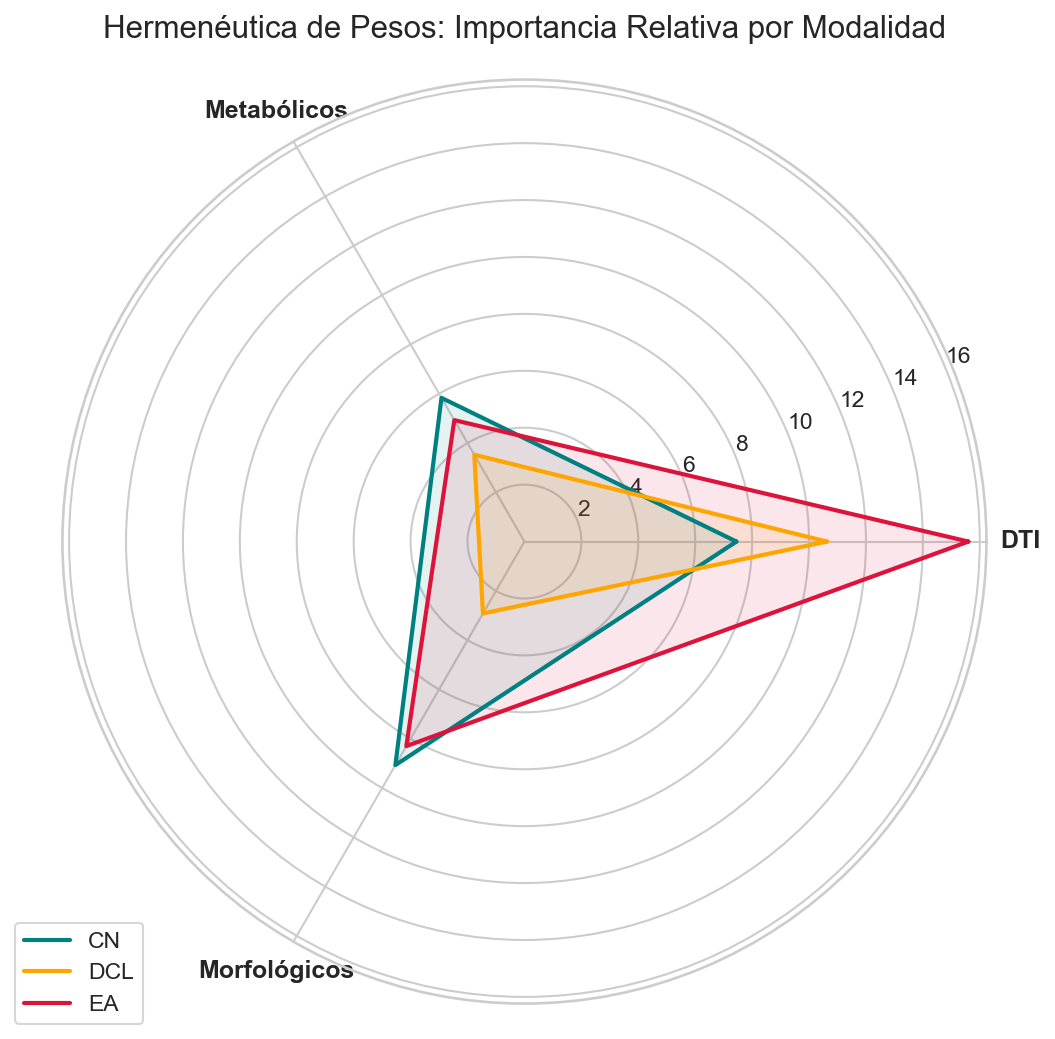

In [2]:
grafico_radar_pesos('pesos_meta_modelo_por_algoritmo.csv')